# Homework 4

## Problem 0

### 0

In [1]:
import scipy
import numpy as np
import pandas as pd
from fractions import Fraction as frac
from scipy import stats
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (15,10)
t = np.linspace(0, np.pi*100, int(1e5))
N = 10 + np.sin(t)
sqrtN = np.sqrt(N)
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N)+N

## Problem 1

### 1A


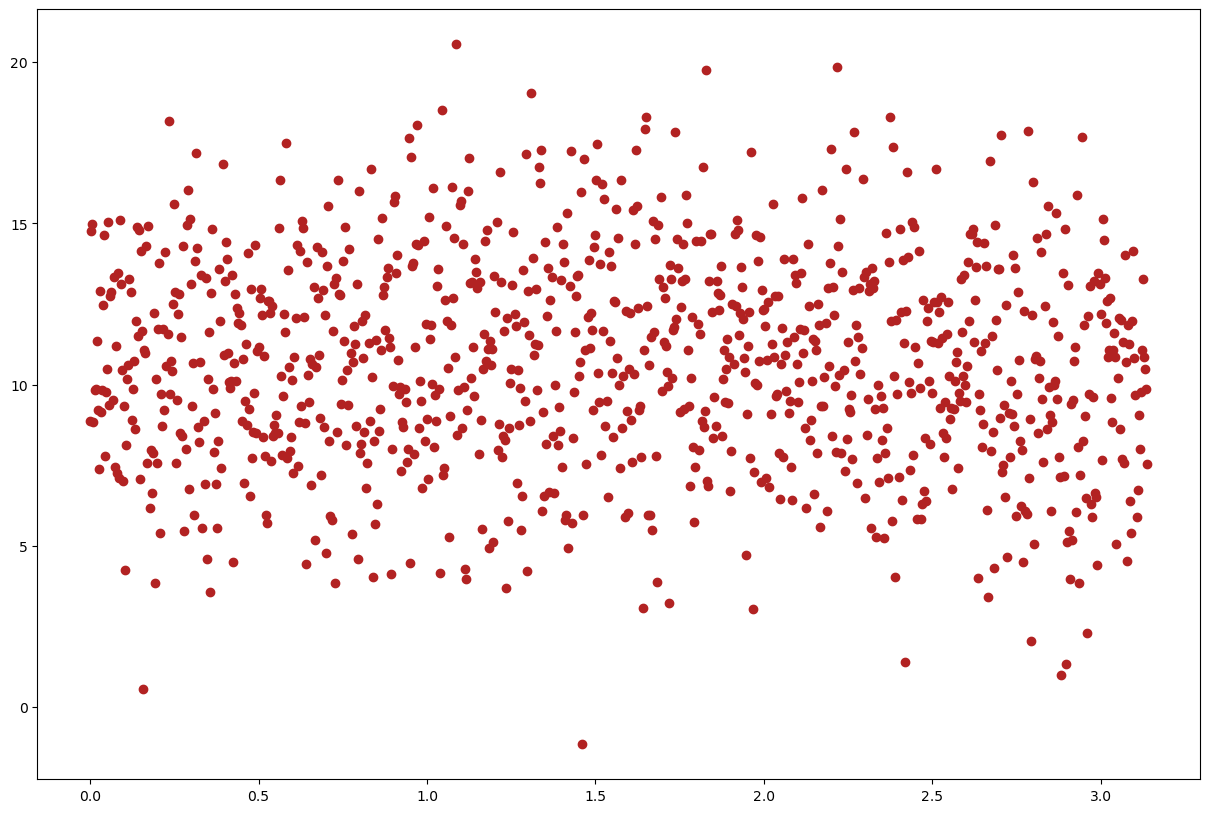

"fig, ax = plt.subplots()\nax.scatter(t[:10000], sqrtN[:10000], color = 'firebrick')\nplt.show()"

In [2]:
fig, ax = plt.subplots()
ax.scatter(t[:1000], bkgd[:1000], color = 'firebrick')
plt.show()
'''fig, ax = plt.subplots()
ax.scatter(t[:10000], sqrtN[:10000], color = 'firebrick')
plt.show()'''

Not very sinusoidal. Hmmm...

After finshing the assignment and coming back I suspect this should look more sinusoidal because the data barely shows any pattern...

### 1B

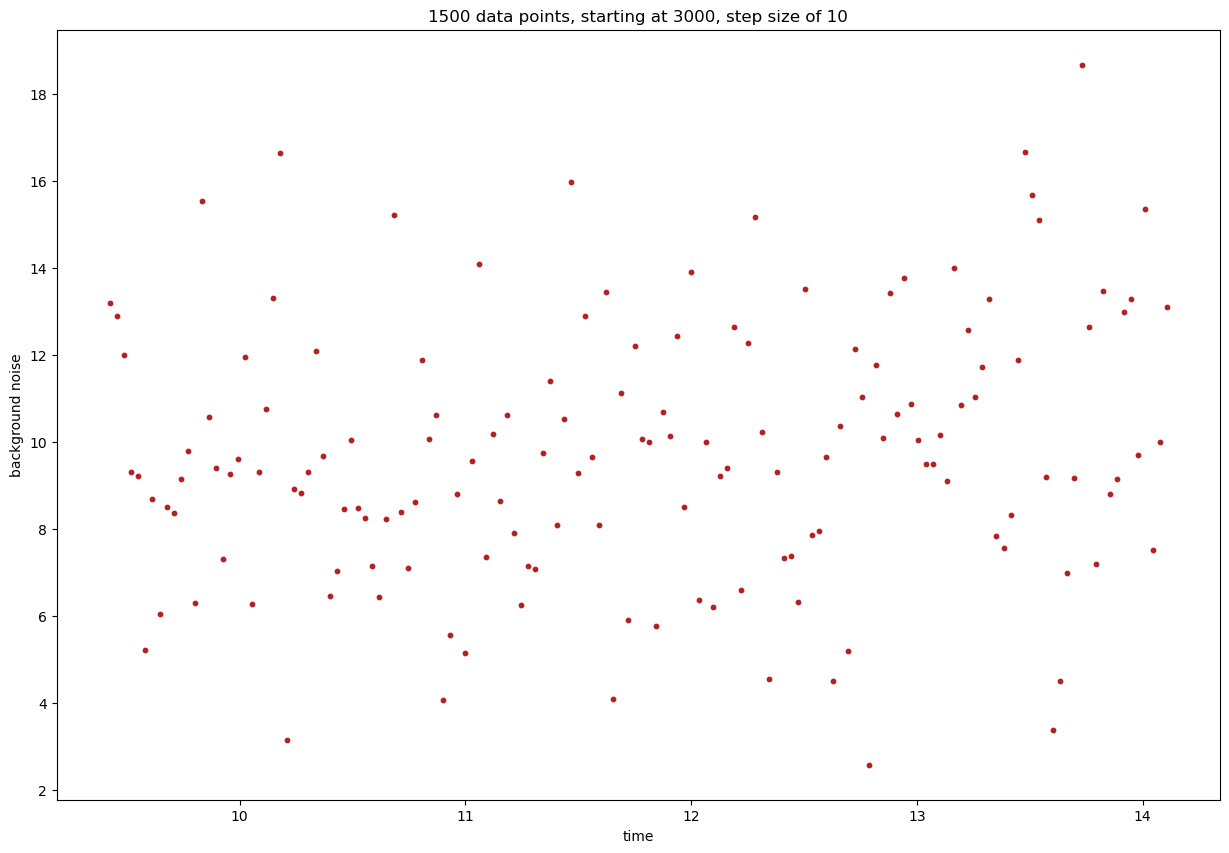

In [3]:
def sinplot(size, init, step, time):
    fig, ax = plt.subplots()
    ax.scatter(time[init:init+size:step], bkgd[init:init+size:step], color = 'firebrick', s = 10)
    ax.set_xlabel('time')
    ax.set_ylabel('background noise')
    ax.set_title(f'{size} data points, starting at {init}, step size of {step}')
    plt.show()

sinplot(1500, 3000, 10, t)

Nice. Very Jackson Pollock, or maybe Lee Krasner.

### 1C

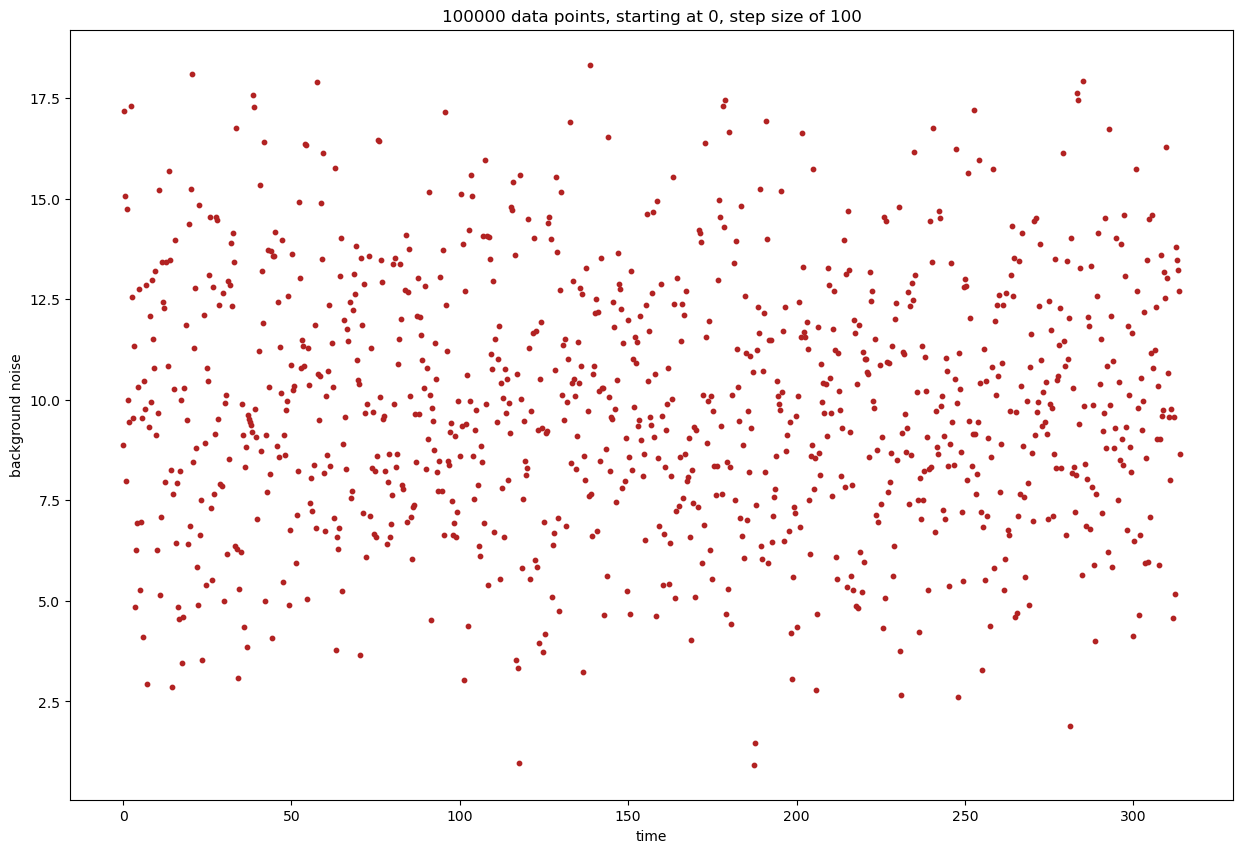

In [4]:
sinplot(t.size, 0, 100, t)

## Problem 2

### 2A

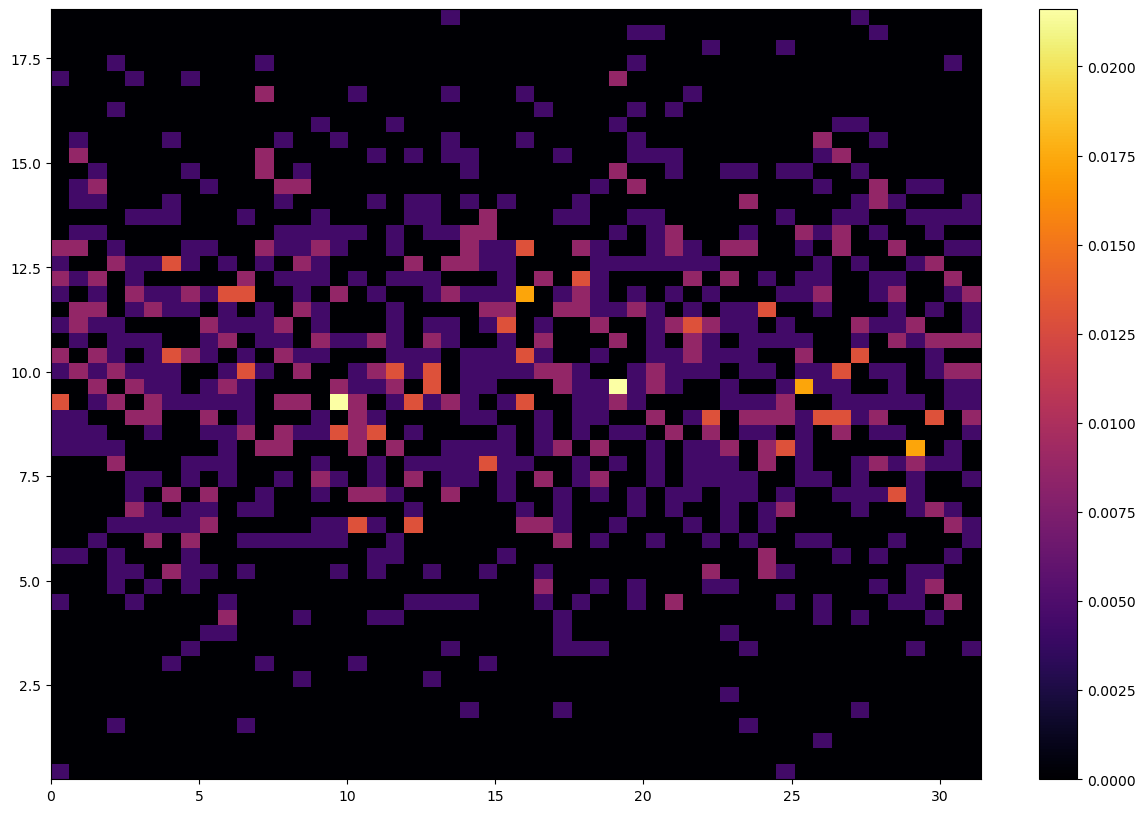

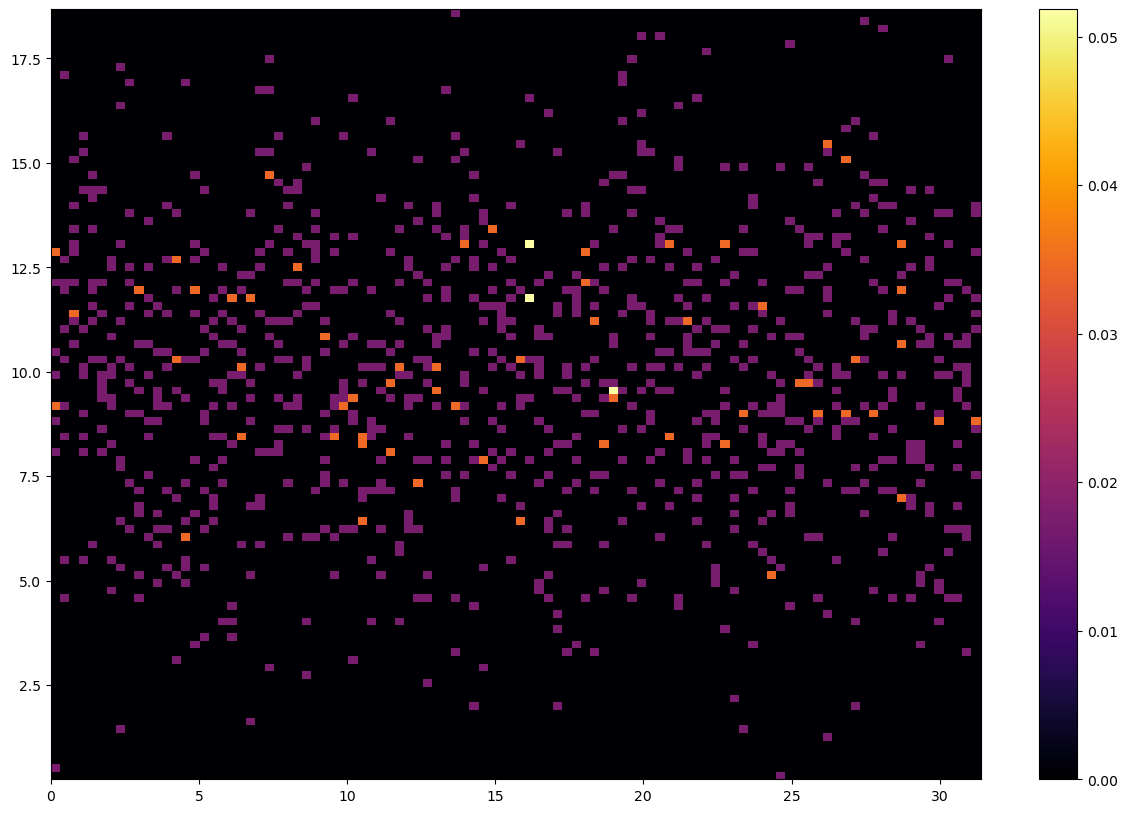

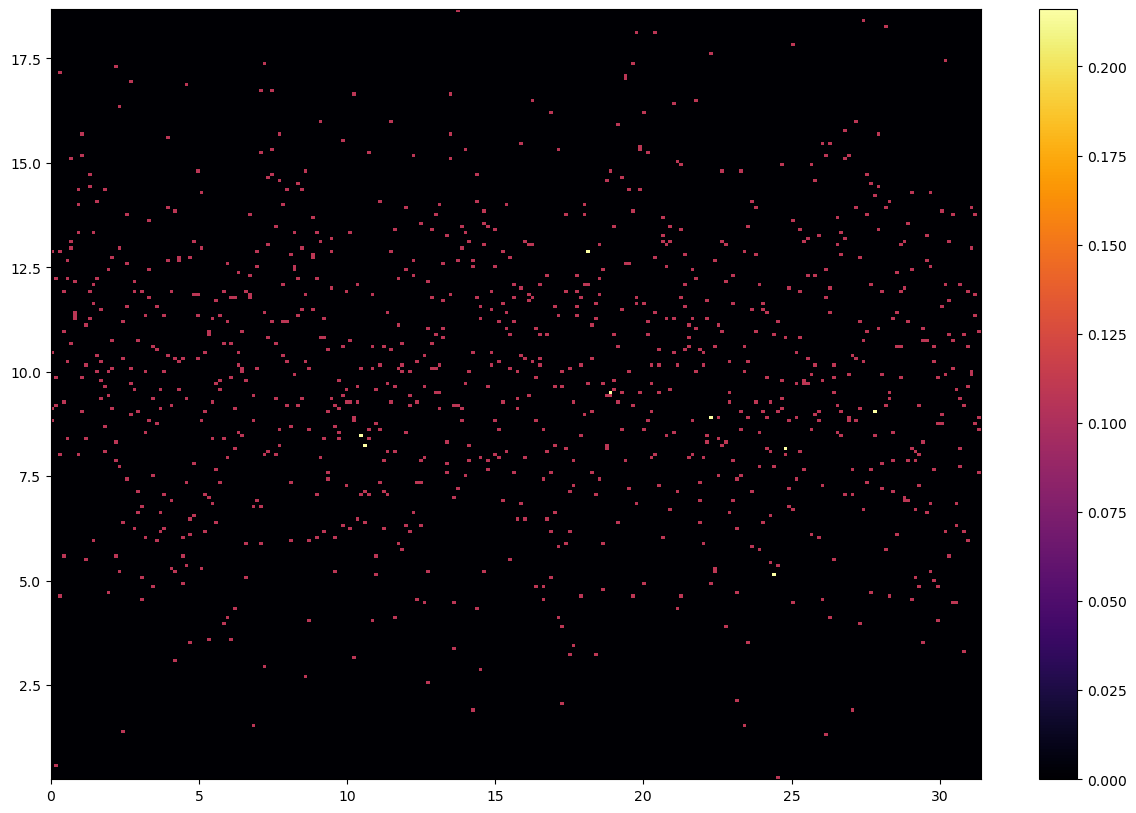

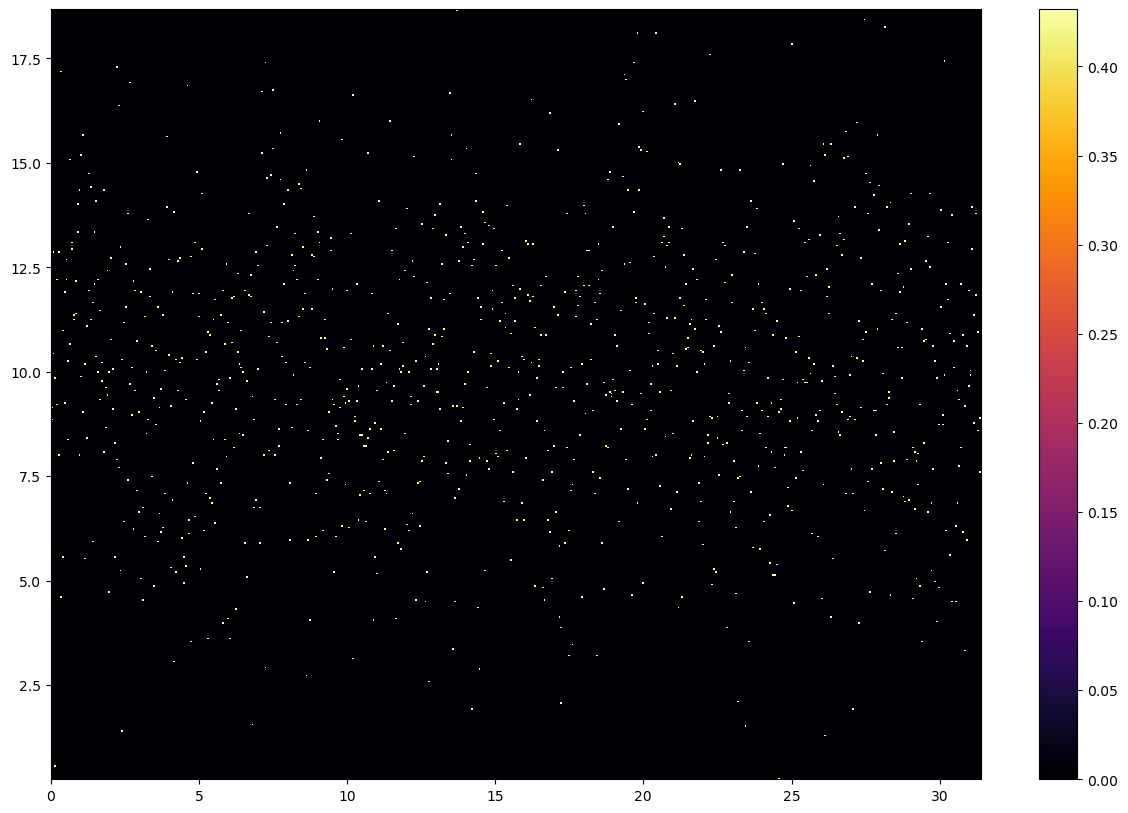

In [5]:
plt.hist2d(t[:10000:10], bkgd[:10000:10], 50, density = True, cmap = 'inferno')
plt.colorbar()
plt.show()
plt.hist2d(t[:10000:10], bkgd[:10000:10], 100, density = True, cmap = 'inferno')
plt.colorbar()
plt.show()
plt.hist2d(t[:10000:10], bkgd[:10000:10], 250, density = True, cmap = 'inferno')
plt.colorbar()
plt.show()
plt.hist2d(t[:10000:10], bkgd[:10000:10], 500, density = True, cmap = 'inferno')
plt.colorbar()
plt.show()

I really dig that inferno colormap. I messed around with several bin numbers and think 100 looks pretty useful.

### 2B

The 2d histogram shows a heatmap of the density of our background data/distribution; for this colormap white/yellow bins are where the data is concentrated most, and black bins are where there is almost no data.

## Problem 3

### 3A

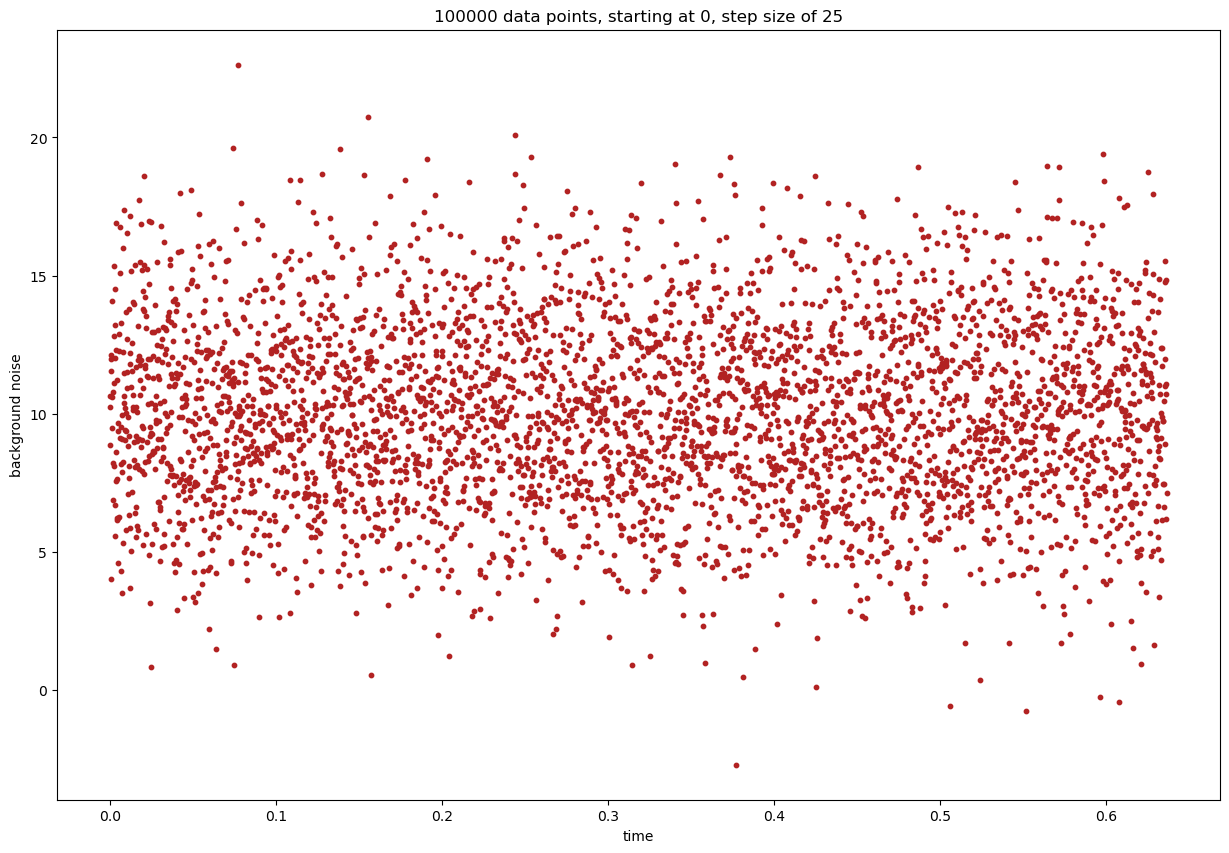

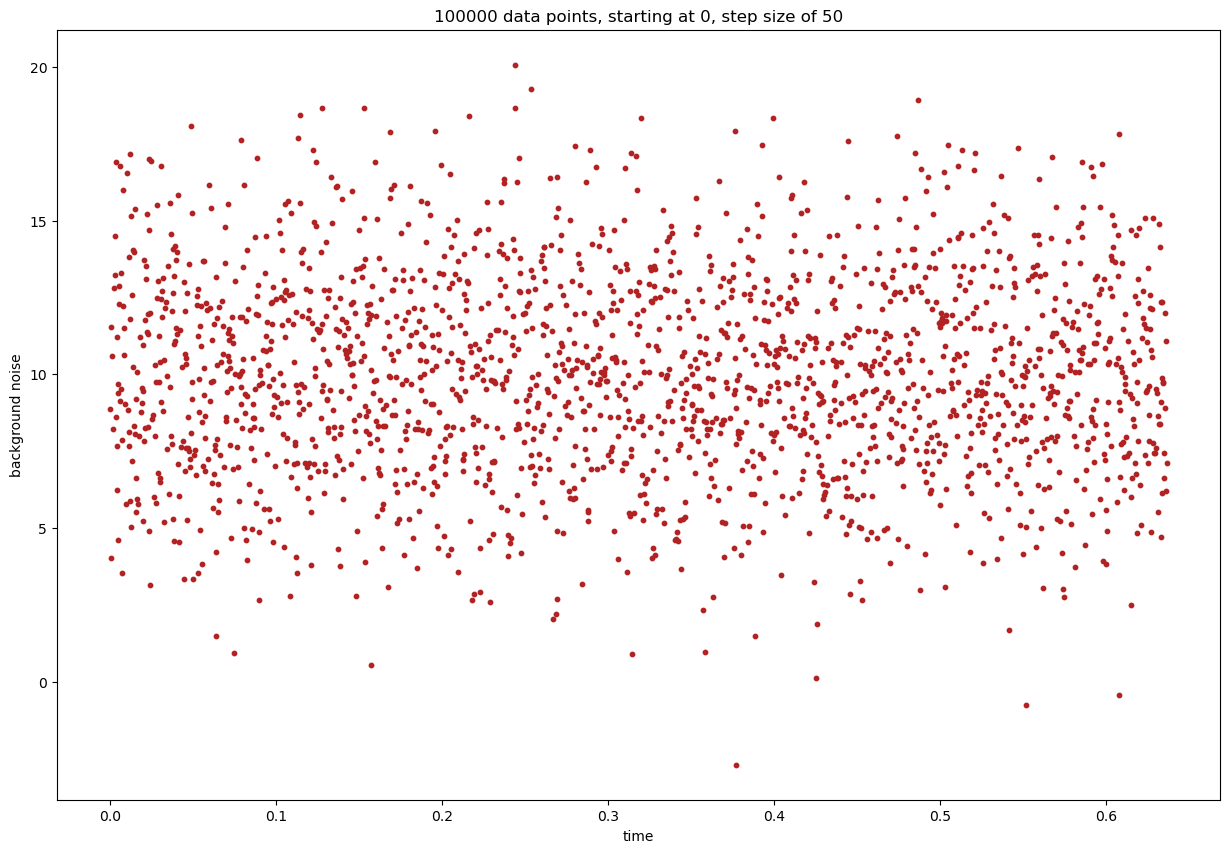

In [6]:
t_fold = t % (2/np.pi)
sinplot(100000, 0, 25, t_fold)
sinplot(100000, 0, 50, t_fold)


Not really sure what to read from this but the technique is cool.

### 3B

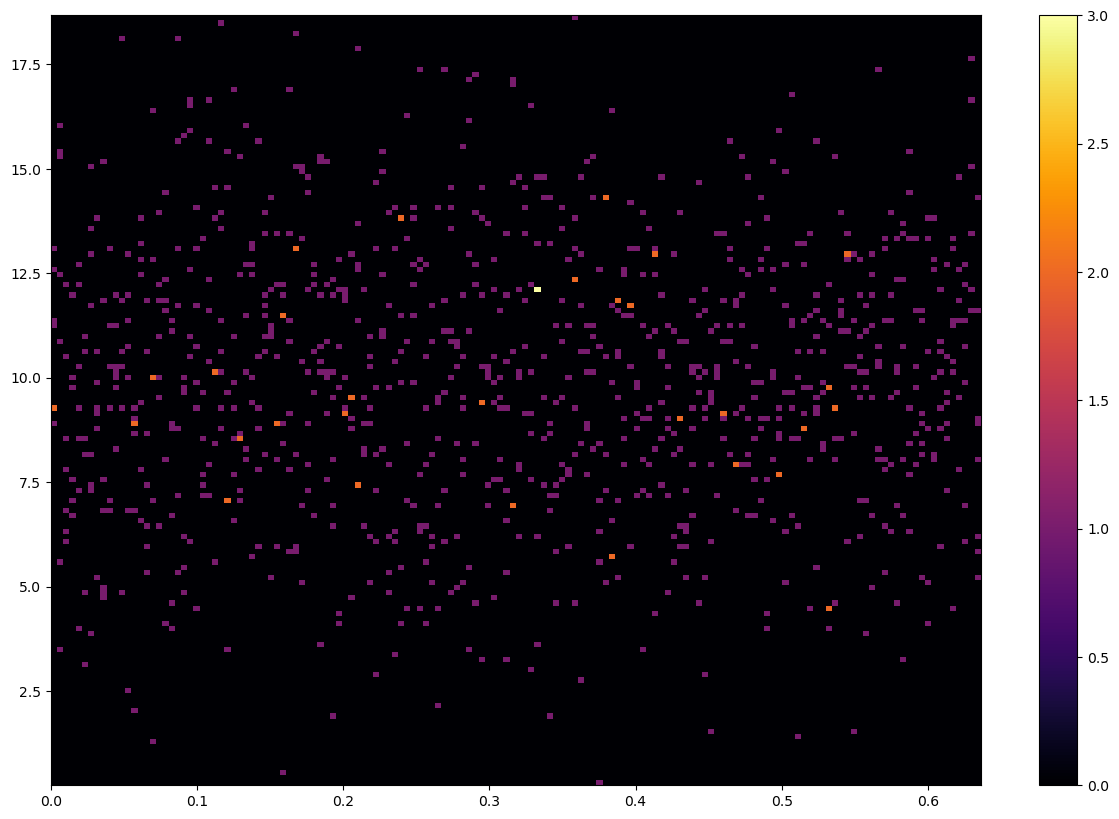

In [7]:
plt.hist2d(t_fold[:10000:10], bkgd[:10000:10], 150, cmap = 'inferno')
plt.colorbar()
plt.show()

Such a nice pixel art feel. I can see that the data is no longer stratified along the period lines, which is useful.

### 3C



In [8]:
zeroes = np.where(t_fold >= 0.63)[0] #trying to find where the period ends, there's almost certainly a better way
print(zeroes[1])
print(t_fold.max())
print(len(zeroes))
average = np.zeros(203)
print(len(average))
for i in range(int(np.floor(100000/203))):
    average += bkgd[i*203:(i+1)*203]/493

202
0.6366073499389806
1038
203


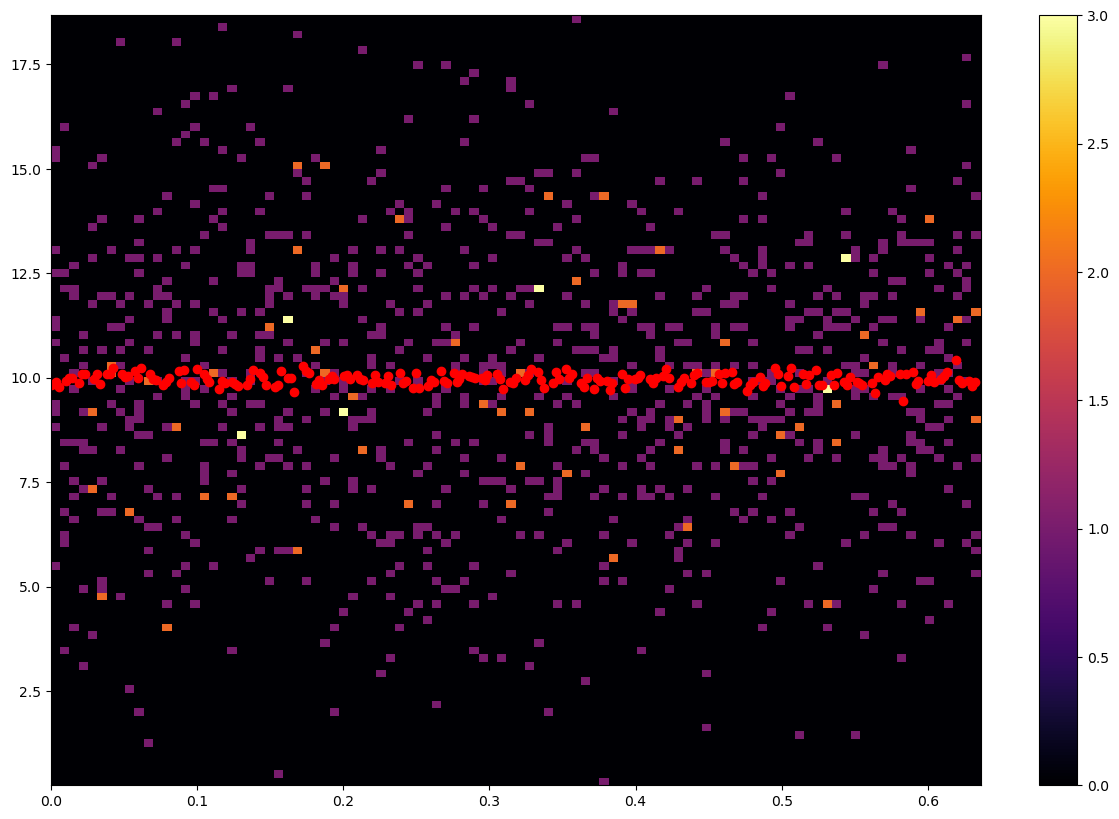

In [9]:
plt.hist2d(t_fold[:10000:10], bkgd[:10000:10], 100, cmap = 'inferno')
plt.colorbar()
plt.scatter(t_fold[::493], average, color = 'red')
plt.show()

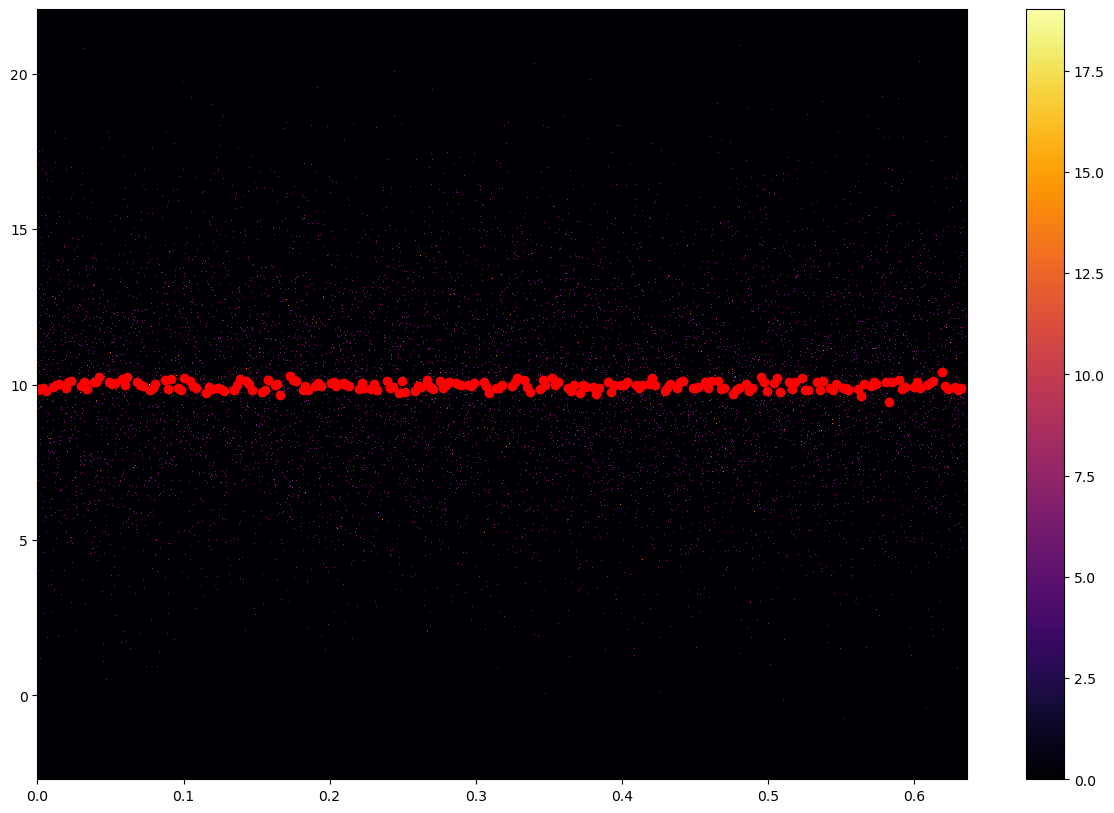

In [10]:
plt.hist2d(t_fold[::10], bkgd[::10], 1000, density = True, cmap = 'inferno')
plt.colorbar()
plt.scatter(t_fold[::493], average, color = 'red')
plt.show()

Yeah, I'm kinda shocked at the shape of the average, it doesn't seem to fit at all. Maybe I didn't do the averaging right but i 